# Лабораторная работа 3
## Прогноз качества вина по CRISP-DM

Я решаю задачу по датасету [Wine Quality на Kaggle](https://www.kaggle.com/datasets/rajyellow46/wine-quality).
В работе последовательно прохожу шесть этапов CRISP-DM: понимание задачи, изучение данных,
подготовку, моделирование, оценку и использование результата.

**Как запустить.** В Jupyter откройте ноутбук в папке этой лабораторной и выполните Restart Kernel → Run All.
Для точного повторения окружения используйте `python -m pip install -r requirements.txt`.
В Colab доступны основные библиотеки; если их не хватает, установите `pandas scikit-learn matplotlib joblib` через `%pip install`.
CSV лежит в `data`. Если открыть только ноутбук в Colab, он скачает ту же версию данных автоматически и проверит SHA-256.
Сохранённые результаты и графики можно просматривать на GitHub без запуска кода.


## 1 Business Understanding — понимание задачи

Представим лабораторию производителя вина. По результатам химических анализов я хочу предварительно
оценивать дегустационный балл и направлять сложные образцы на дополнительную экспертную проверку.
В датасете отсутствуют сведения о затратах и реальном производственном процессе, поэтому экономический
эффект в этой работе я не рассчитываю.

**ML-задача.** Многоклассовая классификация: вход — 11 физико-химических измерений и тип вина,
выход — исходное значение `quality`. Оценки упорядочены, поэтому дополнительно измерю абсолютную ошибку
в баллах. Сохраню исходные классы, не объединяя их в «хорошее» и «плохое» вино.

**Критерии сравнения до эксперимента.** Основная метрика — macro-F1, поскольку редкие оценки также важны.
Дополнительно рассчитаю balanced accuracy, accuracy, MAE и долю ошибок не больше одного балла.
Ориентир учебного эксперимента — превысить macro-F1 простого базового решения хотя бы на 0,10.
Победителя выберу по кросс-валидации на обучающей части. Отложенный тест будет использован после этого выбора.
Пользовательскую пригодность для реальной лаборатории предстоит проверять на независимых производственных данных.


In [1]:
%matplotlib inline
import io
import json
import hashlib
import platform
import time
import zipfile
from pathlib import Path
from urllib.request import Request, urlopen

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import joblib
from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    ConfusionMatrixDisplay, f1_score, make_scorer, mean_absolute_error,
)
from sklearn.model_selection import StratifiedGroupKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
versions = {
    'python': platform.python_version(), 'numpy': np.__version__,
    'pandas': pd.__version__, 'scikit-learn': sklearn.__version__,
    'matplotlib': matplotlib.__version__, 'joblib': joblib.__version__,
}
display(pd.Series(versions, name='Версия'))


python          3.12.14
numpy             2.3.5
pandas            2.2.3
scikit-learn      1.7.2
matplotlib       3.10.7
joblib            1.6.0
Name: Версия, dtype: object

## 2 Data Understanding — изучение данных

Использую именно `winequalityN.csv` версии 1 из указанного в задании набора Kaggle.
Первоначальные данные Wine Quality опубликованы Cortez и соавторами в UCI и относятся к красным и белым
винам Vinho Verde. В UCI задача допускает классификацию и регрессию, классы имеют естественный порядок.
В этой работе фактический состав и пропуски проверяются на файле Kaggle, а не предполагаются по описанию UCI.


In [2]:
EXPECTED_SHA256 = 'cb01f91c70de066f85d4cffac3bb163e4719523861cd79ba8825b722cf98b48c'
KAGGLE_URL = 'https://www.kaggle.com/api/v1/datasets/download/rajyellow46/wine-quality?datasetVersionNumber=1'
REPO_DATA_URL = 'https://raw.githubusercontent.com/Erosha103/video-knowledge/main/labs/lab-03-wine-quality/data/winequalityN.csv'
data_path = Path('data/winequalityN.csv')

def download_bytes(url):
    request = Request(url, headers={'User-Agent': 'kaggle-api/1.7.4'})
    with urlopen(request, timeout=60) as response:
        return response.read()

if not data_path.exists():
    data_path.parent.mkdir(exist_ok=True)
    try:
        archive = zipfile.ZipFile(io.BytesIO(download_bytes(KAGGLE_URL)))
        raw_bytes = archive.read('winequalityN.csv')
    except Exception as kaggle_error:
        print('Kaggle недоступен, загружаю копию того же CSV из репозитория.')
        raw_bytes = download_bytes(REPO_DATA_URL)
    if hashlib.sha256(raw_bytes).hexdigest() != EXPECTED_SHA256:
        raise ValueError('Контрольная сумма скачанного CSV отличается от версии лабораторной.')
    data_path.write_bytes(raw_bytes)

source_sha = hashlib.sha256(data_path.read_bytes()).hexdigest()
assert source_sha == EXPECTED_SHA256, 'Проверьте, что используется исходный CSV версии 1.'
raw = pd.read_csv(data_path)
print('SHA-256 подтверждён. Размер таблицы:', raw.shape)
display(raw.head())


SHA-256 подтверждён. Размер таблицы: (6497, 13)


,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,white,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,white,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,white,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [3]:
schema = pd.DataFrame({
    'тип': raw.dtypes.astype(str),
    'пропуски': raw.isna().sum(),
    'уникальных значений': raw.nunique(dropna=True),
})
display(schema)
print('Полных дубликатов:', raw.duplicated().sum())
display(raw['quality'].value_counts().sort_index().rename('Число образцов'))
display(raw['type'].value_counts().rename('Число образцов'))


,тип,пропуски,уникальных значений
type,object,0,2
fixed acidity,float64,10,106
volatile acidity,float64,8,187
citric acid,float64,3,89
residual sugar,float64,2,316
chlorides,float64,2,214
free sulfur dioxide,float64,0,135
total sulfur dioxide,float64,0,276
density,float64,0,998
pH,float64,9,108


Полных дубликатов: 1168


quality
3      30
4     216
5    2138
6    2836
7    1079
8     193
9       5
Name: Число образцов, dtype: int64

type
white    4898
red      1599
Name: Число образцов, dtype: int64

В файле 6 497 строк и 13 столбцов: целевая оценка, тип вина и 11 числовых признаков.
Примеры измерений — кислотность, содержание сахара, плотность, pH, содержание алкоголя и диоксида серы.
Значения `quality` находятся в диапазоне 3–9. Оценок 5 и 6 существенно больше, чем крайних.
Оценка 9 встречается всего пять раз, поэтому выводы по этому классу будут особенно ненадёжными.

В CSV есть пропуски в семи числовых столбцах и 1 168 полных повторов.
Целевая переменная заполнена. Выбросы автоматически удалять не буду: необычный химический анализ
может быть реальным наблюдением. Основные графики и зависимости построю по обучающей части после разделения данных.


## 3 Data Preparation — подготовка данных

Удаляю полные повторы, чтобы одинаковые записи не завышали оценку качества. Эта операция меняет
вес повторяющихся наблюдений; итог относится к очищенному набору уникальных записей.
Одинаковые наборы входных измерений могут иметь разные оценки, поэтому дополнительно объединяю совпадающие
входы в группы. Разбиение не должно отправлять такую группу одновременно в обучение и тест.
Преобразования признаков будут обучаться внутри Pipeline только на соответствующей обучающей части.


In [4]:
expected_columns = [
    'type', 'fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
    'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
    'pH', 'sulphates', 'alcohol', 'quality',
]
assert raw.columns.tolist() == expected_columns
assert raw['quality'].notna().all()
assert raw['quality'].between(0, 10).all()
assert set(raw['type']) == {'red', 'white'}

data = raw.drop_duplicates().reset_index(drop=True)
X = data.drop(columns='quality')
y = data['quality'].astype(int)
classes = np.sort(y.unique())
numeric_features = X.select_dtypes(include='number').columns.tolist()
categorical_features = ['type']
assert len(numeric_features) == 11
assert np.isfinite(X[numeric_features].to_numpy()[~X[numeric_features].isna()]).all()

# Для группировки использую только входные признаки, без quality.
groups = pd.util.hash_pandas_object(X, index=False).astype(str)
print('После удаления повторов:', data.shape)
print('Групп входных измерений:', groups.nunique())
print('Групп с разными дегустационными оценками:',
      pd.DataFrame({'group': groups, 'quality': y}).groupby('group')['quality'].nunique().gt(1).sum())


После удаления повторов: (5329, 13)
Групп входных измерений: 5329
Групп с разными дегустационными оценками: 0


In [5]:
outer_splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
split_candidates = list(outer_splitter.split(X, y, groups))

# Правило выбора зафиксировано до обучения: первый фолд со всеми классами
# в обеих частях и минимум тремя группами каждого класса в обучении.
for candidate_number, (development_index, test_index) in enumerate(split_candidates):
    development_group_counts = (
        pd.DataFrame({'quality': y.iloc[development_index], 'group': groups.iloc[development_index]})
        .groupby('quality')['group'].nunique()
    )
    if (set(y.iloc[development_index]) == set(classes)
            and set(y.iloc[test_index]) == set(classes)
            and development_group_counts.min() >= 3):
        break
else:
    raise ValueError('Не удалось получить разбиение со всеми классами.')

X_development, X_test = X.iloc[development_index].copy(), X.iloc[test_index].copy()
y_development, y_test = y.iloc[development_index].copy(), y.iloc[test_index].copy()
groups_development = groups.iloc[development_index]
assert set(groups_development).isdisjoint(set(groups.iloc[test_index]))

inner_splitter = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED + 1)
cv_splits = list(inner_splitter.split(X_development, y_development, groups_development))
for train_index, validation_index in cv_splits:
    assert set(groups_development.iloc[train_index]).isdisjoint(
        set(groups_development.iloc[validation_index]))

split_counts = pd.DataFrame({
    'обучение и CV': y_development.value_counts(),
    'отложенный тест': y_test.value_counts(),
}).reindex(classes).fillna(0).astype(int)
print('Выбран внешний фолд:', candidate_number)
print('Обучение и CV:', len(X_development), '| Тест:', len(X_test))
display(split_counts)
cv_class_counts = pd.DataFrame({
    f'CV fold {i + 1}': y_development.iloc[validation_index].value_counts()
    for i, (_, validation_index) in enumerate(cv_splits)
}).reindex(classes).fillna(0).astype(int)
display(cv_class_counts)


Выбран внешний фолд: 1
Обучение и CV: 4263 | Тест: 1066


,обучение и CV,отложенный тест
quality,,
3,24,6
4,161,45
5,1399,356
6,1887,440
7,672,185
8,116,33
9,4,1


,CV fold 1,CV fold 2,CV fold 3
quality,,,
3,7,5,12
4,68,47,46
5,469,461,469
6,623,633,631
7,224,234,214
8,30,38,48
9,0,3,1


Я выделил примерно 20% данных для итогового теста и использую трёхкратную групповую кросс-валидацию
на остальных данных. Числа в таблице выше позволяют проверить доли и наличие редких классов.
Правило выбора внешнего фолда зависит от состава классов, а не от результатов моделей.

Группировка защищает от точных совпадений измерений. Идентификаторов партий и отдельных образцов в файле нет,
поэтому возможную зависимость близких анализов полностью исключить нельзя. Перенос результата на новые партии
вина потребует отдельной проверки.
Групповая стратификация сохраняет доли приближённо: редкий класс может отсутствовать в отдельном
валидационном фолде. Таблица выше показывает эти случаи. Macro-F1 во всех фолдах усредняется по одним и тем же
семи классам, а значение для отсутствующего класса принимается равным нулю.


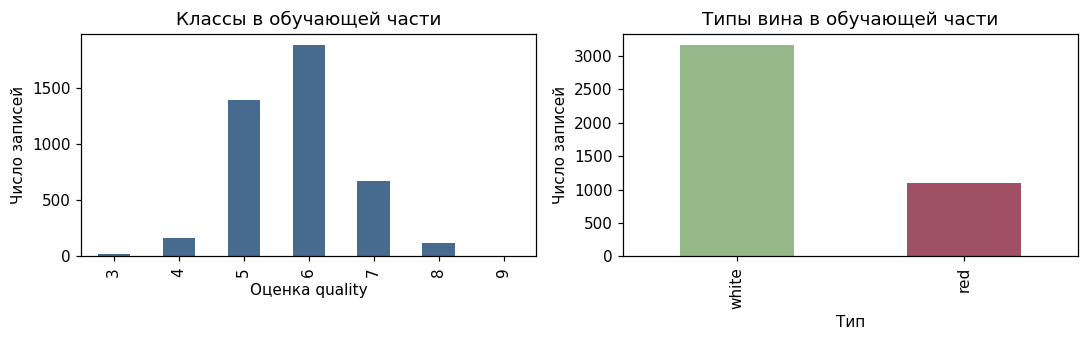

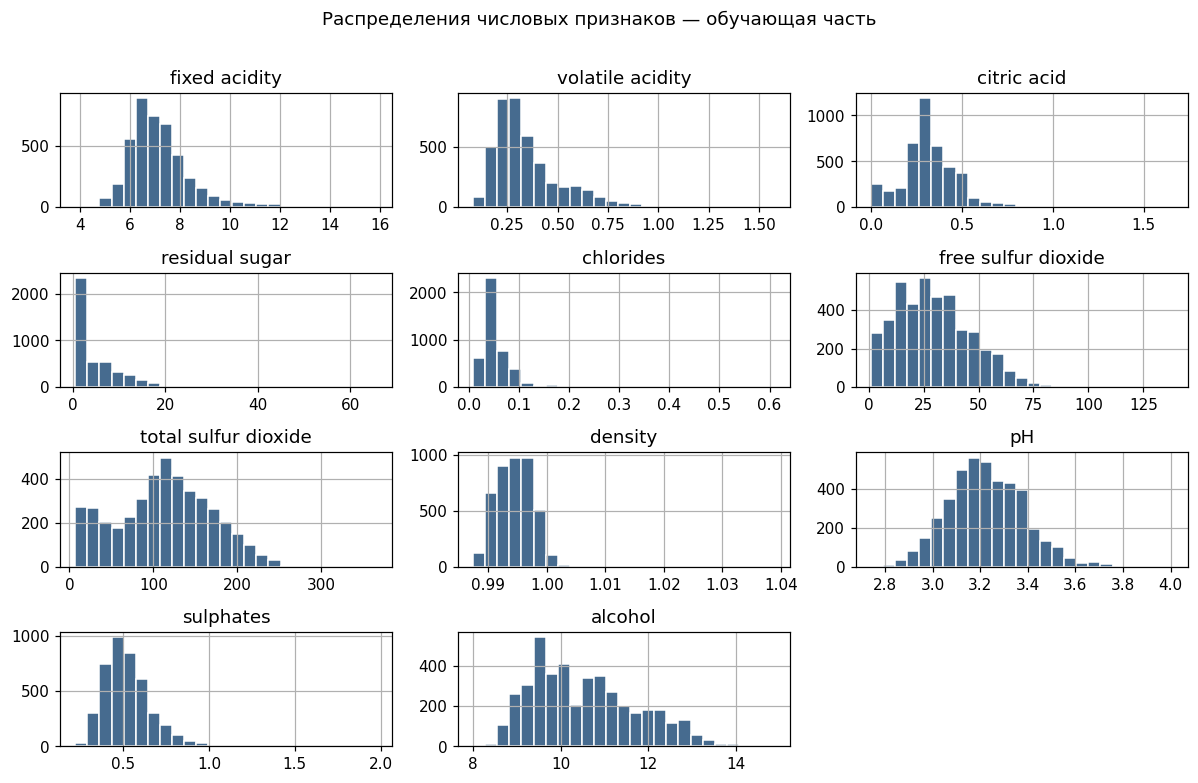

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
y_development.value_counts().sort_index().plot.bar(ax=axes[0], color='#466b8f')
axes[0].set(title='Классы в обучающей части', xlabel='Оценка quality', ylabel='Число записей')
X_development['type'].value_counts().plot.bar(ax=axes[1], color=['#94b887', '#9f5064'])
axes[1].set(title='Типы вина в обучающей части', xlabel='Тип', ylabel='Число записей')
plt.tight_layout()
plt.show()

X_development[numeric_features].hist(figsize=(11, 7), bins=25, color='#466b8f', edgecolor='white')
plt.suptitle('Распределения числовых признаков — обучающая часть', y=1.01)
plt.tight_layout()
plt.show()


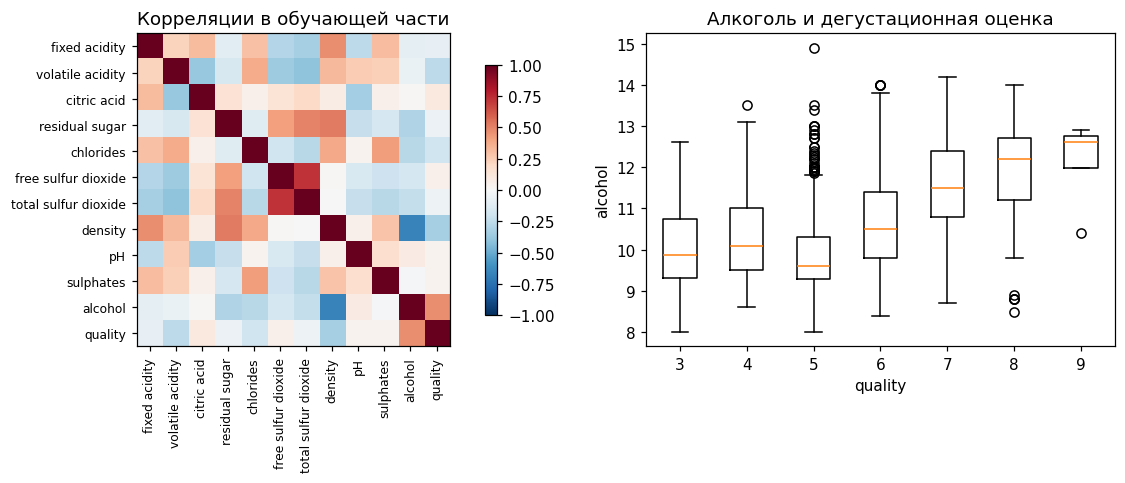

alcohol                 0.468387
citric acid             0.098469
free sulfur dioxide     0.054381
sulphates               0.037685
pH                      0.033193
total sulfur dioxide   -0.053753
residual sugar         -0.059227
fixed acidity          -0.079181
chlorides              -0.198436
volatile acidity       -0.259369
density                -0.330308
Name: Корреляция с quality, dtype: float64

In [7]:
development_table = X_development.assign(quality=y_development)
correlations = development_table[numeric_features + ['quality']].corr()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={'width_ratios': [1.5, 1]})
image = axes[0].imshow(correlations, vmin=-1, vmax=1, cmap='RdBu_r')
axes[0].set_xticks(range(len(correlations)), correlations.columns, rotation=90, fontsize=8)
axes[0].set_yticks(range(len(correlations)), correlations.index, fontsize=8)
axes[0].set_title('Корреляции в обучающей части')
fig.colorbar(image, ax=axes[0], shrink=0.8)
alcohol_samples = [development_table.loc[development_table.quality == q, 'alcohol'].dropna() for q in classes]
axes[1].boxplot(alcohol_samples, tick_labels=classes)
axes[1].set(title='Алкоголь и дегустационная оценка', xlabel='quality', ylabel='alcohol')
plt.tight_layout()
plt.show()
display(correlations['quality'].drop('quality').sort_values(ascending=False).rename('Корреляция с quality'))


На графиках я смотрю на дисбаланс классов, масштабы и асимметрию признаков.
Корреляции показывают связи в этих данных и не доказывают, что изменение одного вещества само по себе
улучшит качество вина. Из-за различий масштабов линейной модели понадобится стандартизация.
Деревьям она обычно не нужна. Пропуски заполню медианами внутри обучающего конвейера,
а тип вина преобразую в индикаторы категорий.


In [8]:
def make_preprocessor(scale_numeric):
    numeric_steps = [('imputer', SimpleImputer(strategy='median', add_indicator=True))]
    if scale_numeric:
        numeric_steps.append(('scaler', StandardScaler()))
    return ColumnTransformer([
        ('numeric', Pipeline(numeric_steps), numeric_features),
        ('type', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features),
    ])

macro_f1 = make_scorer(f1_score, labels=classes, average='macro', pos_label=None, zero_division=0)
scoring = {'macro_f1': macro_f1, 'accuracy': 'accuracy'}


## 4 Modeling — обучение и сравнение моделей

Я сравниваю три подхода на одинаковых фолдах:

- `DummyClassifier` всегда выбирает наиболее частый класс и задаёт простую точку отсчёта.
- `LogisticRegression` даёт линейную модель; веса классов учитывают дисбаланс.
- `RandomForestClassifier` позволяет учитывать нелинейные связи и взаимодействия измерений.

Для линейной модели переберу три значения C. Для леса проверю два размера листа и два варианта весов классов.
Количество деревьев фиксирую заранее. Это небольшой перебор, который можно повторить на обычном CPU.
Все медианы и параметры стандартизации заново оцениваются внутри обучающего фолда.


In [9]:
baseline = Pipeline([
    ('prepare', make_preprocessor(False)),
    ('model', DummyClassifier(strategy='most_frequent')),
])
baseline_cv = cross_validate(baseline, X_development, y_development, cv=cv_splits,
                             scoring=scoring, error_score='raise')
cv_rows = [{
    'model': 'DummyClassifier',
    'macro_f1_mean': baseline_cv['test_macro_f1'].mean(),
    'macro_f1_std': baseline_cv['test_macro_f1'].std(),
    'accuracy_mean': baseline_cv['test_accuracy'].mean(),
    'parameters': 'most_frequent',
}]

model_specs = {
    'LogisticRegression': (
        Pipeline([('prepare', make_preprocessor(True)),
                  ('model', LogisticRegression(class_weight='balanced', max_iter=3000, random_state=SEED))]),
        {'model__C': [0.1, 1.0, 10.0]},
    ),
    'RandomForest': (
        Pipeline([('prepare', make_preprocessor(False)),
                  ('model', RandomForestClassifier(n_estimators=250, random_state=SEED, n_jobs=2))]),
        {'model__min_samples_leaf': [1, 3], 'model__class_weight': [None, 'balanced_subsample']},
    ),
}
searches = {}
for name, (pipeline, parameter_grid) in model_specs.items():
    started = time.perf_counter()
    search = GridSearchCV(pipeline, parameter_grid, cv=cv_splits, scoring=scoring,
                          refit='macro_f1', n_jobs=1, error_score='raise', return_train_score=True)
    search.fit(X_development, y_development)
    searches[name] = search
    index = search.best_index_
    cv_rows.append({
        'model': name,
        'macro_f1_mean': search.cv_results_['mean_test_macro_f1'][index],
        'macro_f1_std': search.cv_results_['std_test_macro_f1'][index],
        'accuracy_mean': search.cv_results_['mean_test_accuracy'][index],
        'parameters': json.dumps(search.best_params_, ensure_ascii=False),
    })
    print(name, '| секунд:', round(time.perf_counter() - started, 1), '| параметры:', search.best_params_)

cv_results = pd.DataFrame(cv_rows).set_index('model').sort_values('macro_f1_mean', ascending=False)
display(cv_results.round(4))


LogisticRegression | секунд: 0.4 | параметры: {'model__C': 10.0}


RandomForest | секунд: 5.1 | параметры: {'model__class_weight': 'balanced_subsample', 'model__min_samples_leaf': 3}


,macro_f1_mean,macro_f1_std,accuracy_mean,parameters
model,,,,
RandomForest,0.2874,0.0040,0.5569,"{""model__class_weight"": ""balanced_subsample"", ..."
LogisticRegression,0.2298,0.0151,0.3455,"{""model__C"": 10.0}"
DummyClassifier,0.0877,0.0004,0.4426,most_frequent


По кросс-валидации я выбрал **RandomForest**. Macro-F1 = **0.287**, прирост к базовому решению = **0.200**. Эти значения относятся к выбору модели. Независимая оценка будет получена на отложенном тесте.

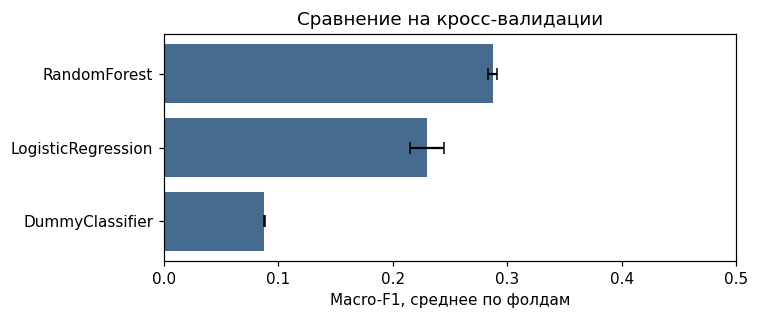

In [10]:
best_name = max(searches, key=lambda name: searches[name].best_score_)
best_search = searches[best_name]
best_model = best_search.best_estimator_
best_cv_score = float(best_search.best_score_)
cv_baseline_score = float(baseline_cv['test_macro_f1'].mean())
cv_gain = best_cv_score - cv_baseline_score
display(Markdown(
    f'По кросс-валидации я выбрал **{best_name}**. '
    f'Macro-F1 = **{best_cv_score:.3f}**, прирост к базовому решению = **{cv_gain:.3f}**. '
    'Эти значения относятся к выбору модели. Независимая оценка будет получена на отложенном тесте.'
))
fig, ax = plt.subplots(figsize=(7, 3))
ordered = cv_results.sort_values('macro_f1_mean')
ax.barh(ordered.index, ordered.macro_f1_mean, xerr=ordered.macro_f1_std,
        color='#466b8f', capsize=4)
ax.set(xlabel='Macro-F1, среднее по фолдам', title='Сравнение на кросс-валидации')
ax.set_xlim(0, max(0.5, float(ordered.macro_f1_mean.max()) + 0.12))
plt.tight_layout()
plt.show()


## 5 Evaluation — проверка результата

Архитектура, параметры и правило выбора уже определены без использования качества на тесте.
Теперь оцениваю выбранную модель и базовое решение на одном отложенном наборе.
Macro-F1 считаю по всем исходным классам, включая редкие. Balanced accuracy — средняя полнота по классам.
MAE учитывает порядок оценок: ошибка на два балла серьёзнее ошибки на один.


In [11]:
baseline.fit(X_development, y_development)
prediction = best_model.predict(X_test)
baseline_prediction = baseline.predict(X_test)

def evaluate(y_true, y_pred):
    absolute_errors = np.abs(np.asarray(y_true) - np.asarray(y_pred))
    return {
        'macro_f1': f1_score(y_true, y_pred, labels=classes, average='macro', zero_division=0),
        'balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
        'accuracy': accuracy_score(y_true, y_pred),
        'mae_points': mean_absolute_error(y_true, y_pred),
        'within_one_point': float((absolute_errors <= 1).mean()),
    }

test_results = pd.DataFrame({
    best_name: evaluate(y_test, prediction),
    'DummyClassifier': evaluate(y_test, baseline_prediction),
}).T
display(test_results.round(4))
report = pd.DataFrame(classification_report(
    y_test, prediction, labels=classes, output_dict=True, zero_division=0)).T
display(report.round(3))


,macro_f1,balanced_accuracy,accuracy,mae_points,within_one_point
RandomForest,0.2979,0.2861,0.5469,0.4962,0.9625
DummyClassifier,0.0835,0.1429,0.4128,0.6735,0.9203


,precision,recall,f1-score,support
3,0.000,0.000,0.000,6.000
4,0.462,0.267,0.338,45.000
5,0.616,0.640,0.628,356.000
6,0.532,0.586,0.558,440.000
7,0.459,0.449,0.454,185.000
8,0.500,0.061,0.108,33.000
9,0.000,0.000,0.000,1.000
accuracy,0.547,0.547,0.547,0.547
macro avg,0.367,0.286,0.298,1066.000
weighted avg,0.540,0.547,0.536,1066.000


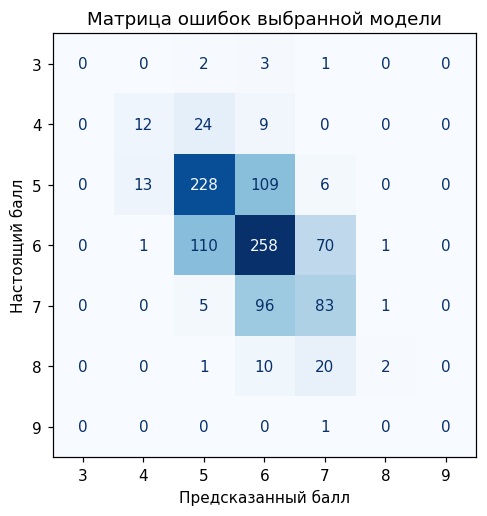

,n,accuracy,mae_points,within_one_point
type,,,,
red,263,0.586,0.452,0.966
white,803,0.534,0.511,0.961


In [12]:
fig, ax = plt.subplots(figsize=(6, 4.8))
ConfusionMatrixDisplay.from_predictions(y_test, prediction, labels=classes,
                                       cmap='Blues', colorbar=False, ax=ax)
ax.set(title='Матрица ошибок выбранной модели', xlabel='Предсказанный балл', ylabel='Настоящий балл')
plt.tight_layout()
plt.show()

test_by_type = []
for wine_type in ['red', 'white']:
    mask = X_test['type'].eq(wine_type).to_numpy()
    metrics = evaluate(y_test.iloc[np.flatnonzero(mask)], prediction[mask])
    metrics = {key: metrics[key] for key in ['accuracy', 'mae_points', 'within_one_point']}
    test_by_type.append({'type': wine_type, 'n': int(mask.sum()), **metrics})
display(pd.DataFrame(test_by_type).set_index('type').round(3))


,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,actual,predicted,absolute_error
215,white,5.8,0.24,0.44,3.5,0.029,5.0,109.0,0.99130,3.53,0.43,11.7,3,7,4
2718,white,9.4,0.24,0.29,8.5,0.037,124.0,208.0,0.99395,2.90,0.38,11.0,3,6,3
1198,white,8.2,0.22,0.36,6.8,0.034,12.0,90.0,0.99440,3.01,0.38,10.5,8,5,3
3836,white,6.1,0.26,0.25,2.9,0.047,289.0,440.0,0.99314,3.44,0.64,10.5,3,6,3
4688,red,10.4,0.44,0.42,1.5,0.145,34.0,48.0,0.99832,3.38,0.86,9.9,3,6,3
4926,red,6.5,0.58,0.00,2.2,0.096,3.0,13.0,0.99557,3.62,0.62,11.5,4,6,2
2375,white,5.8,0.21,0.32,1.6,0.045,38.0,95.0,0.98946,3.23,0.94,12.4,8,6,2
885,white,8.2,0.68,0.30,2.1,0.047,17.0,138.0,0.99500,3.22,0.71,10.8,4,6,2
670,white,5.8,0.34,0.16,7.0,0.037,26.0,116.0,0.99490,3.46,0.45,10.0,7,5,2
1030,white,9.2,0.28,0.41,1.0,0.042,14.0,59.0,0.99220,2.96,0.25,10.5,6,4,2


,feature,mean_drop_macro_f1,std
11,alcohol,0.0655,0.0063
6,free sulfur dioxide,0.0340,0.0032
2,volatile acidity,0.0300,0.0069
10,sulphates,0.0275,0.0045
3,citric acid,0.0215,0.0030
5,chlorides,0.0169,0.0022
7,total sulfur dioxide,0.0161,0.0087
8,density,0.0109,0.0023
1,fixed acidity,0.0099,0.0062
0,type,0.0078,0.0037


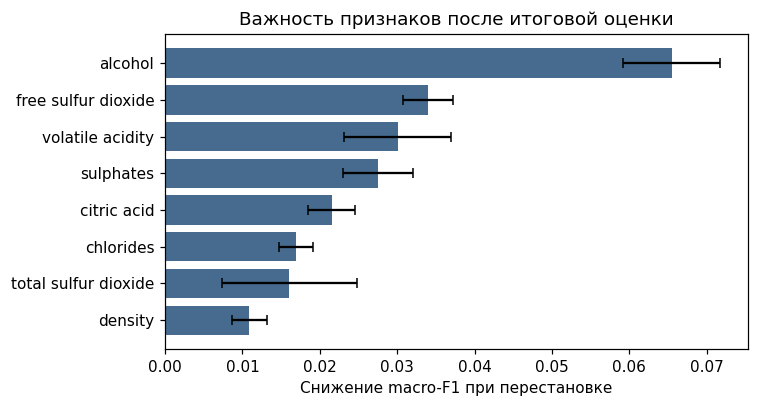

In [13]:
diagnostics = X_test.copy()
diagnostics['actual'] = y_test
diagnostics['predicted'] = prediction
diagnostics['absolute_error'] = np.abs(y_test.to_numpy() - prediction)
display(diagnostics.sort_values('absolute_error', ascending=False).head(10))

permutation = permutation_importance(best_model, X_test, y_test, scoring=macro_f1,
                                     n_repeats=3, random_state=SEED, n_jobs=1)
feature_importance = pd.DataFrame({
    'feature': X_test.columns,
    'mean_drop_macro_f1': permutation.importances_mean,
    'std': permutation.importances_std,
}).sort_values('mean_drop_macro_f1', ascending=False)
display(feature_importance.round(4))
fig, ax = plt.subplots(figsize=(7, 3.8))
top = feature_importance.head(8).sort_values('mean_drop_macro_f1')
ax.barh(top.feature, top.mean_drop_macro_f1, xerr=top['std'], color='#466b8f', capsize=3)
ax.set(title='Важность признаков после итоговой оценки', xlabel='Снижение macro-F1 при перестановке')
plt.tight_layout()
plt.show()


Перестановочная важность используется здесь для разбора уже выбранной модели.
По тестовым важностям я не меняю признаки и параметры. Сильные корреляции между измерениями
могут распределять важность между ними; эти результаты не являются доказательством причинного влияния.


In [14]:
model_metrics = test_results.loc[best_name]
baseline_metrics = test_results.loc['DummyClassifier']
test_gain = float(model_metrics['macro_f1'] - baseline_metrics['macro_f1'])
goal_passed = test_gain >= 0.10
rare_classes = report.loc[[str(q) for q in classes], ['recall', 'support']]
zero_recall_classes = ', '.join(rare_classes.index[rare_classes['recall'].eq(0)]) or 'нет'
top_features = ', '.join(feature_importance.head(3).feature)
display(Markdown(
    f'### Вывод по результатам\n\n'
    f'На отложенном тесте **{best_name}** получил macro-F1 **{model_metrics["macro_f1"]:.3f}** '
    f'и accuracy **{model_metrics["accuracy"]:.1%}**. '
    f'Средняя абсолютная ошибка составила **{model_metrics["mae_points"]:.3f} балла**; '
    f'доля ответов с ошибкой не больше одного балла — **{model_metrics["within_one_point"]:.1%}**.\n\n'
    f'Прирост macro-F1 относительно DummyClassifier равен **{test_gain:.3f}**. '
    f'Заранее выбранный ориентир +0,10 **{"достигнут" if goal_passed else "не достигнут"}**. '
    f'Наиболее заметные перестановочные важности у признаков **{top_features}**.\n\n'
    f'Классы с нулевой полнотой на этом тесте: **{zero_recall_classes}**. '
    'Качество по всем семи классам остаётся ограниченным. '
    'Высокую долю ошибок не более одного балла нужно читать вместе с результатом базового решения. '
    'Пяти исходных наблюдений с оценкой 9 недостаточно для устойчивого вывода о качестве распознавания этого класса. '
    'Даже при хорошем общем результате модель требует дополнительной проверки перед применением в реальной лаборатории.'
))
display(rare_classes)


### Вывод по результатам

На отложенном тесте **RandomForest** получил macro-F1 **0.298** и accuracy **54.7%**. Средняя абсолютная ошибка составила **0.496 балла**; доля ответов с ошибкой не больше одного балла — **96.2%**.

Прирост macro-F1 относительно DummyClassifier равен **0.214**. Заранее выбранный ориентир +0,10 **достигнут**. Наиболее заметные перестановочные важности у признаков **alcohol, free sulfur dioxide, volatile acidity**.

Классы с нулевой полнотой на этом тесте: **3, 9**. Качество по всем семи классам остаётся ограниченным. Высокую долю ошибок не более одного балла нужно читать вместе с результатом базового решения. Пяти исходных наблюдений с оценкой 9 недостаточно для устойчивого вывода о качестве распознавания этого класса. Даже при хорошем общем результате модель требует дополнительной проверки перед применением в реальной лаборатории.

,recall,support
3,0.000000,6.0
4,0.266667,45.0
5,0.640449,356.0
6,0.586364,440.0
7,0.448649,185.0
8,0.060606,33.0
9,0.000000,1.0


## 6 Deployment — использование результата

Для учебного применения я сохраняю весь обученный Pipeline, параметры и результаты.
Ниже загружаю сохранённый файл и выполняю один прогноз. Это демонстрация на образце из тестового набора,
а не проверка на новом производстве. Модель обучена на обучающей части; после итогового теста я её не перенастраиваю.

Перед использованием в лаборатории потребуется проверить данные новых партий, согласовать допустимые ошибки
с экспертом и контролировать распределения признаков, пропуски и ошибки по классам. Оценки, для которых мало
примеров, следует направлять на ручную проверку. Подтверждённые новые оценки можно собирать для следующего
цикла CRISP-DM и нового независимого теста.


In [15]:
joblib.dump(best_model, ARTIFACTS / 'wine_quality_pipeline.joblib')
loaded_model = joblib.load(ARTIFACTS / 'wine_quality_pipeline.joblib')

def predict_quality(measurements):
    required = set(X.columns)
    if set(measurements) != required:
        raise ValueError(f'Поля должны совпадать со схемой: {sorted(required)}')
    if measurements['type'] not in {'red', 'white'}:
        raise ValueError('Поддерживаются типы red и white.')
    sample = pd.DataFrame([measurements], columns=X.columns)
    return int(loaded_model.predict(sample)[0])

sample_index = X_test.index[0]
sample_measurements = X_test.loc[sample_index].to_dict()
sample_prediction = predict_quality(sample_measurements)
display(pd.DataFrame([{
    'пример': 'Один образец отложенного теста',
    'quality_actual': int(y_test.loc[sample_index]),
    'quality_predicted': sample_prediction,
}]))
assert np.array_equal(loaded_model.predict(X_test), prediction)
print('После сохранения и загрузки прогнозы совпадают.')


,пример,quality_actual,quality_predicted
0,Один образец отложенного теста,6,5


После сохранения и загрузки прогнозы совпадают.


In [16]:
summary = {
    'dataset': 'rajyellow46/wine-quality', 'dataset_version': 1, 'sha256': source_sha,
    'seed': SEED, 'raw_rows': len(raw), 'unique_rows': len(data),
    'full_duplicates_removed': int(raw.duplicated().sum()),
    'missing_cells': int(raw.isna().sum().sum()),
    'development_rows': len(X_development), 'test_rows': len(X_test),
    'classes': [int(q) for q in classes], 'chosen_model': best_name,
    'best_parameters': best_search.best_params_, 'cv_macro_f1': best_cv_score,
    'test_metrics': {name: float(value) for name, value in model_metrics.items()},
    'baseline_test_metrics': {name: float(value) for name, value in baseline_metrics.items()},
    'test_macro_f1_gain': test_gain, 'goal_passed': bool(goal_passed), 'versions': versions,
}
(ARTIFACTS / 'run_summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
cv_results.to_csv(ARTIFACTS / 'cv_results.csv')
test_results.to_csv(ARTIFACTS / 'test_metrics.csv')
diagnostics.to_csv(ARTIFACTS / 'test_predictions.csv', index=False)
print('Сохранены модель, сводка и таблицы результатов в artifacts/.')
assert len(prediction) == len(y_test)
assert set(prediction).issubset(set(classes))
assert 'quality' not in X_test.columns
assert set(groups_development).isdisjoint(set(groups.iloc[test_index]))
print('Проверки схемы, прогнозов и разделения групп пройдены.')


Сохранены модель, сводка и таблицы результатов в artifacts/.
Проверки схемы, прогнозов и разделения групп пройдены.


## Источники

1. [Wine Quality, Raj Parmar — Kaggle](https://www.kaggle.com/datasets/rajyellow46/wine-quality), файл `winequalityN.csv`, версия 1.
2. [Cortez и соавторы, Wine Quality — UCI](https://archive.ics.uci.edu/dataset/186/wine-quality), DOI [10.24432/C56S3T](https://doi.org/10.24432/C56S3T).
   Первоначальные данные UCI распространяются по CC BY 4.0. Для работы использован указанный вариант Kaggle с пропусками.
3. [IBM, CRISP-DM Guide](https://www.ibm.com/docs/en/SS3RA7_19.0.0/pdf/ModelerCRISPDM.pdf), описание шести этапов и итеративного процесса.
4. [scikit-learn, StratifiedGroupKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html).
5. [scikit-learn, Pipeline и защита от утечки](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).
6. [scikit-learn, F1 score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html).
7. [scikit-learn, permutation_importance](https://scikit-learn.org/stable/modules/permutation_importance.html).

В работе я прошёл все этапы CRISP-DM и получил проверяемый результат обучения.
Следующее улучшение потребует новых независимых примеров, особенно для редких оценок, и проверки на реальных партиях.
